# Nobel Prize Dataset: Data Analysis Notebook

This notebook explores the Nobel Prize winners dataset and discovers at least 12 different analytical insights.


In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_theme(style='whitegrid')

df = pd.read_csv('nobel_prize_winners.csv')
df.head()

,awardYear,category,categoryFullName,sortOrder,portion,prizeAmount,prizeAmountAdjusted,dateAwarded,prizeStatus,motivation,...,org_founded_country,org_founded_countryNow,org_founded_locationString,ind_or_org,residence_1,residence_2,affiliation_1,affiliation_2,affiliation_3,affiliation_4
0,2001,Economic Sciences,The Sveriges Riksbank Prize in Economic Scienc...,2,1/3,10000000,12295082,2001-10-10,received,for their analyses of markets with asymmetric ...,...,NaN,NaN,NaN,Individual,NaN,NaN,"Stanford University, Stanford, CA, USA",NaN,NaN,NaN
1,1975,Physics,The Nobel Prize in Physics,1,1/3,630000,3404179,1975-10-17,received,for the discovery of the connection between co...,...,NaN,NaN,NaN,Individual,NaN,NaN,"Niels Bohr Institute, Copenhagen, Denmark",NaN,NaN,NaN
2,2004,Chemistry,The Nobel Prize in Chemistry,1,1/3,10000000,11762861,2004-10-06,received,for the discovery of ubiquitin-mediated protei...,...,NaN,NaN,NaN,Individual,NaN,NaN,"Technion - Israel Institute of Technology, Hai...",NaN,NaN,NaN
3,1982,Chemistry,The Nobel Prize in Chemistry,1,1,1150000,3102518,1982-10-18,received,for his development of crystallographic electr...,...,NaN,NaN,NaN,Individual,NaN,NaN,"MRC Laboratory of Molecular Biology, Cambridge...",NaN,NaN,NaN
4,1979,Physics,The Nobel Prize in Physics,2,1/3,800000,2988048,1979-10-15,received,for their contributions to the theory of the u...,...,NaN,NaN,NaN,Individual,NaN,NaN,"International Centre for Theoretical Physics, ...","Imperial College, London, United Kingdom",NaN,NaN


## A. Data Understanding

The dataset contains many Nobel Prize records. It includes award year, category, reward amount, gender, birth country, organization information, and individual/organization identity data.

Important columns include `awardYear`, `category`, `categoryFullName`, `gender`, `birth_country`, `birth_countryNow`, `fullName`, `ind_or_org`, `orgName`, `affiliation_1`, and `birth_date`.


In [38]:
df.shape
df.dtypes
df.describe(include='all')
df.isna().sum()

awardYear                       0
category                        0
categoryFullName                0
sortOrder                       0
portion                         0
prizeAmount                     0
prizeAmountAdjusted             0
dateAwarded                   417
prizeStatus                     0
motivation                      0
categoryTopMotivation         930
award_link                      0
id                              0
name                            0
knownName                      27
givenName                      27
familyName                     29
fullName                       27
penName                       939
gender                         27
laureate_link                   0
birth_date                     27
birth_city                     28
birth_cityNow                  28
birth_continent                27
birth_country                  27
birth_countryNow               27
birth_locationString           27
death_date                    320
death_city    

## B. Data Quality and Preprocessing

The dataset has inconsistent missing values in text columns such as gender and birth country. A few geographic labels are repeated in different forms. We will standardize a few columns and create a `decade` column for longitudinal analysis.


In [39]:
outdir = Path('nobel_figures')
outdir.mkdir(exist_ok=True)

# Normalize categorical text fields
df['gender'] = df['gender'].fillna('Unknown')
df['birth_country'] = df['birth_country'].fillna('Unknown')
df['birth_countryNow'] = df['birth_countryNow'].fillna('Unknown')
df['category'] = df['category'].astype(str)
df['decade'] = (df['awardYear'] // 10) * 10

df['birth_year'] = pd.to_datetime(df['birth_date'], errors='coerce').dt.year
df['age_awarded'] = (df['awardYear'] - df['birth_year'])
df['age_awarded'] = df['age_awarded'].clip(lower=0)

# A clean display-ready copy
df_clean = df.copy()
df_clean.head()

C:\Users\Asus\AppData\Local\Temp\ipykernel_17972\433487813.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['birth_year'] = pd.to_datetime(df['birth_date'], errors='coerce').dt.year


,awardYear,category,categoryFullName,sortOrder,portion,prizeAmount,prizeAmountAdjusted,dateAwarded,prizeStatus,motivation,...,ind_or_org,residence_1,residence_2,affiliation_1,affiliation_2,affiliation_3,affiliation_4,decade,birth_year,age_awarded
0,2001,Economic Sciences,The Sveriges Riksbank Prize in Economic Scienc...,2,1/3,10000000,12295082,2001-10-10,received,for their analyses of markets with asymmetric ...,...,Individual,NaN,NaN,"Stanford University, Stanford, CA, USA",NaN,NaN,NaN,2000,NaN,NaN
1,1975,Physics,The Nobel Prize in Physics,1,1/3,630000,3404179,1975-10-17,received,for the discovery of the connection between co...,...,Individual,NaN,NaN,"Niels Bohr Institute, Copenhagen, Denmark",NaN,NaN,NaN,1970,1922.0,53.0
2,2004,Chemistry,The Nobel Prize in Chemistry,1,1/3,10000000,11762861,2004-10-06,received,for the discovery of ubiquitin-mediated protei...,...,Individual,NaN,NaN,"Technion - Israel Institute of Technology, Hai...",NaN,NaN,NaN,2000,1947.0,57.0
3,1982,Chemistry,The Nobel Prize in Chemistry,1,1,1150000,3102518,1982-10-18,received,for his development of crystallographic electr...,...,Individual,NaN,NaN,"MRC Laboratory of Molecular Biology, Cambridge...",NaN,NaN,NaN,1980,1926.0,56.0
4,1979,Physics,The Nobel Prize in Physics,2,1/3,800000,2988048,1979-10-15,received,for their contributions to the theory of the u...,...,Individual,NaN,NaN,"International Centre for Theoretical Physics, ...","Imperial College, London, United Kingdom",NaN,NaN,1970,1926.0,53.0


### Insight #1

Question: Are Nobel Prize winners mainly male or female?

Analysis: I inspected the gender distribution using `value_counts()` and a bar chart.

Visualization: Bar chart of gender counts.

Finding: The dataset shows a strong male majority, while female winners are a small minority.

Interpretation: The data indicates an imbalance, but also suggests that a deeper category-by-category view is required because gender representation can differ by field.

Follow-up: Does the same dominance remain inside each individual Nobel Prize category?


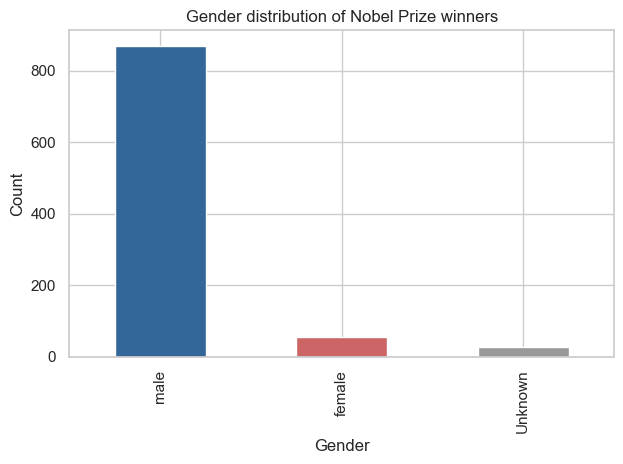

In [40]:
gender_counts = df_clean['gender'].value_counts(dropna=False)
gender_counts.plot(kind='bar', color=['#336699','#CC6666','#999999'])
plt.title('Gender distribution of Nobel Prize winners')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig(outdir / 'insight1_gender_distribution.png')
plt.show()


### Insight #2

Question: Is the gender imbalance the same across Nobel Prize categories?

Analysis: I grouped by `category` and `gender`, then measured female share within each category.

Visualization: Heatmap of female share across categories.

Finding: Some fields such as Peace and Literature show higher female representation than Physics or Economics, while others are almost entirely male.

Interpretation: A single headline gender split hides major differences across disciplines.

Follow-up: Which category had the most rapid improvement in female representation over time?


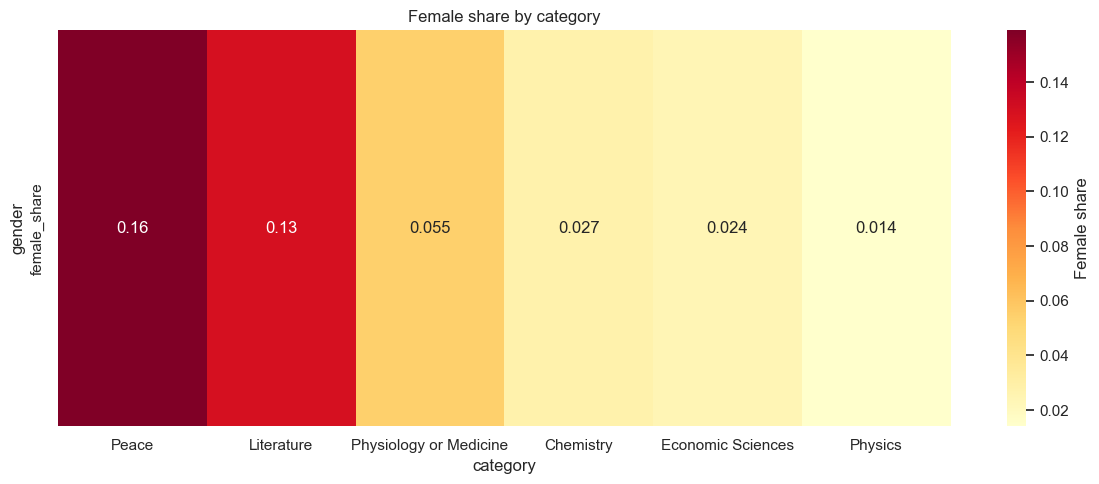

In [41]:
gender_category = df_clean[df_clean['gender'] != 'Unknown'].groupby(['category','gender']).size().unstack(fill_value=0)
gender_category['female_share'] = gender_category.get('female', 0) / (gender_category.get('female', 0) + gender_category.get('male', 0))
category_female = gender_category[['female_share']].sort_values('female_share', ascending=False)
plt.figure(figsize=(12,5))
sns.heatmap(category_female.T, annot=True, cmap='YlOrRd', cbar_kws={'label':'Female share'})
plt.title('Female share by category')
plt.tight_layout()
plt.savefig(outdir / 'insight2_category_female_heatmap.png')
plt.show()

### Insight #3

Question: Has female representation increased across decades?

Analysis: I computed female share by award decade using `groupby('decade')` and age classification, then plotted the trend line.

Visualization: Line chart of female ratio by decade.

Finding: Female participation slowly rises across time, especially from the mid-20th century onward.

Interpretation: The improvement is part of a long historical shift, but the category differences remain important.

Follow-up: Which categories improved most sharply in female share?


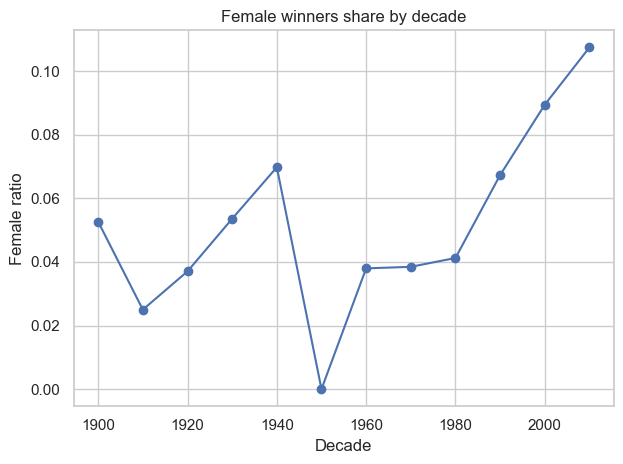

In [42]:
female_by_decade = df_clean[df_clean['gender'].eq('female')].groupby('decade').size()
total_by_decade = df_clean.groupby('decade').size()
female_ratio_by_decade = (female_by_decade / total_by_decade).fillna(0)
female_ratio_by_decade.plot(kind='line', marker='o')
plt.title('Female winners share by decade')
plt.xlabel('Decade')
plt.ylabel('Female ratio')
plt.tight_layout()
plt.savefig(outdir / 'insight3_female_ratio_by_decade.png')
plt.show()

### Insight #4

Question: Which countries produce the most Nobel Prize winners?

Analysis: I counted `birth_country` values and compared the largest countries.

Visualization: Horizontal bar chart of top birth countries.

Finding: The United States leads by a large margin, followed by the United Kingdom and Germany.

Interpretation: Country concentration is very high, but this ranking can hide that some countries dominate only a few categories or certain periods.

Follow-up: Did the country ranking change across century-long time segments?


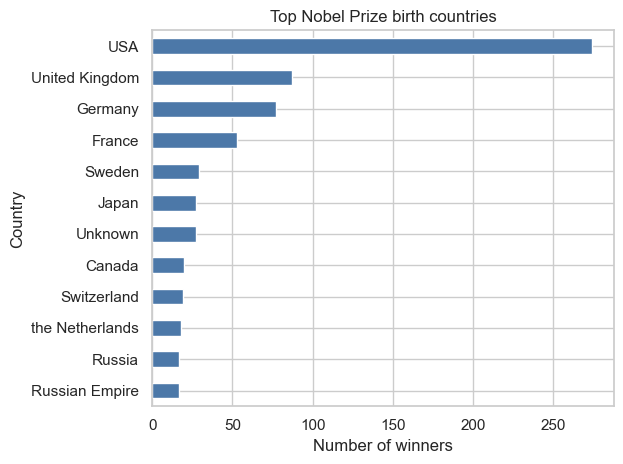

In [43]:
country_counts = df_clean['birth_country'].dropna().str.strip().value_counts().head(12)
country_counts.sort_values().plot(kind='barh', color='#4C78A8')
plt.title('Top Nobel Prize birth countries')
plt.xlabel('Number of winners')
plt.ylabel('Country')
plt.tight_layout()
plt.savefig(outdir / 'insight4_top_countries.png')
plt.show()

### Insight #5

Question: Does the geographic dominance of countries change over time?

Analysis: I created a decade-by-country heatmap that counts winners by `decade` and birth country.

Visualization: Heatmap of decades × top countries.

Finding: The United States becomes dominant in later decades; European countries dominate earlier periods.

Interpretation: The spread of Nobel recognition changed historically; the dataset records both long Western dominance and later global expansion.

Follow-up: Which categories are most responsible for the US growth?


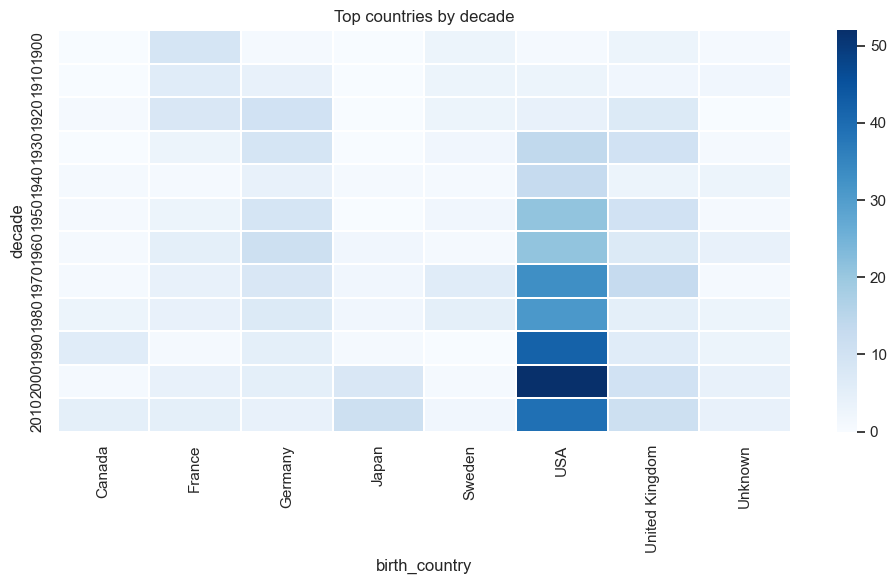

In [44]:
top_countries = df_clean['birth_country'].dropna().value_counts().head(8).index.tolist()
country_decade = df_clean[df_clean['birth_country'].isin(top_countries)].groupby(['decade', 'birth_country']).size().unstack(fill_value=0)
plt.figure(figsize=(10,6))
sns.heatmap(country_decade, cmap='Blues', linewidths=0.2)
plt.title('Top countries by decade')
plt.tight_layout()
plt.savefig(outdir / 'insight5_country_decade_heatmap.png')
plt.show()

### Insight #6

Question: How has category-level interest changed over time?

Analysis: I counted the number of laureates per category by decade and visualized the change as a stacked trend.

Visualization: Grouped line chart / stacked area by category.

Finding: Physics, Chemistry, Medicine, and Literature remain historically central, while Peace and Economics show different time patterns.

Interpretation: Category attention shifts reflect both historical context and changes in which scientific fields government and institutions support.

Follow-up: Which category produced the largest average age difference among winners?


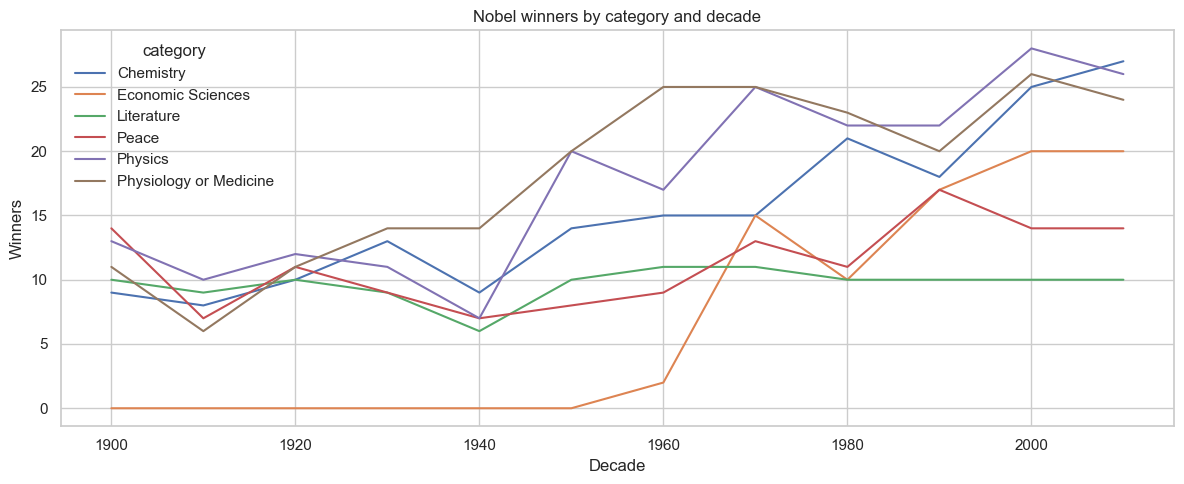

In [45]:
cat_decade = df_clean.groupby(['decade','category']).size().unstack(fill_value=0)
cat_decade.plot(kind='line', figsize=(12,5))
plt.title('Nobel winners by category and decade')
plt.xlabel('Decade')
plt.ylabel('Winners')
plt.tight_layout()
plt.savefig(outdir / 'insight6_category_by_decade.png')
plt.show()

### Insight #7

Question: Is age at award related to the Nobel category?

Analysis: I computed age at award from birth year and award year and compared age distributions by category.

Visualization: Boxplot of age-at-award by category.

Finding: Literature and Peace prizes are often awarded to older or more established leaders, while Physics and Chemistry are more heavily represented by younger scientists.

Interpretation: The category-specific age structure traces differences in field career paths and institutional recognition timing.

Follow-up: How does age compare between male and female laureates within categories?


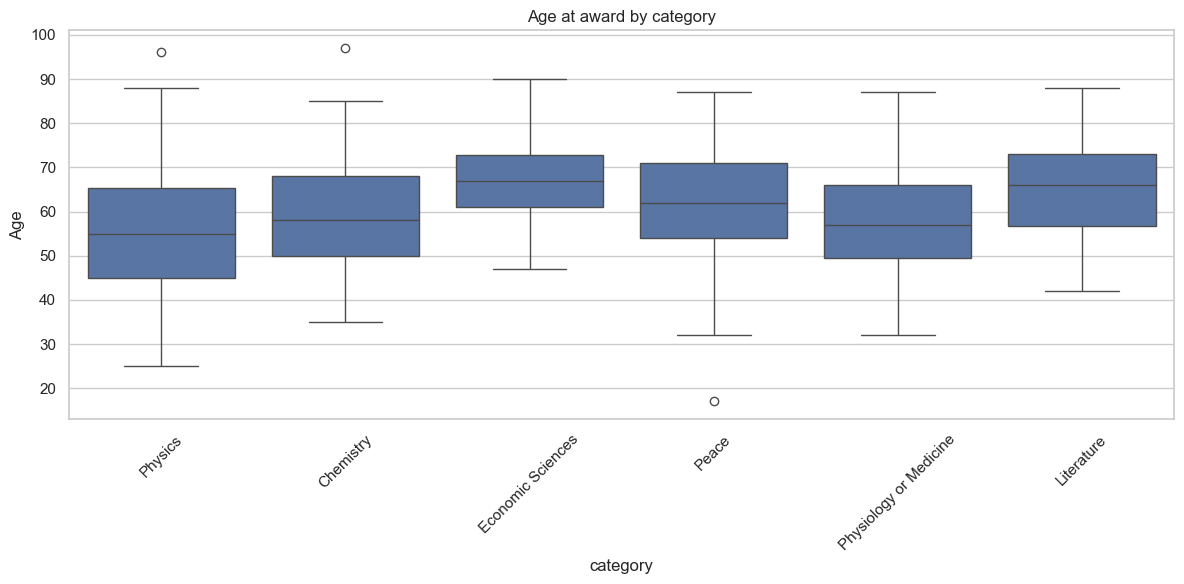

In [46]:
df_clean['age_awarded'] = df_clean['age_awarded'].astype(float)
plt.figure(figsize=(12,6))
sns.boxplot(data=df_clean[df_clean['age_awarded'].notna()], x='category', y='age_awarded')
plt.xticks(rotation=45)
plt.title('Age at award by category')
plt.ylabel('Age')
plt.tight_layout()
plt.savefig(outdir / 'insight7_age_boxplot_by_category.png')
plt.show()

### Insight #8

Question: Are the same people being recognized more than once?

Analysis: I grouped by `fullName` and searched for repeated names in the dataset.

Visualization: Table listing repeat laureates.

Finding: A small group of names repeats, including Marie Curie and John Bardeen.

Interpretation: A repeat winner list highlights exceptional recognition rather than common patterns. It also reveals that the dataset records humans and organizations, not always one-time awards.

Follow-up: How do repeated winners compare to one-time winners by category and country?


In [47]:
repeat_counts = df_clean.groupby('fullName').size().reset_index(name='count')
repeat_list = repeat_counts[repeat_counts['count'] > 1].sort_values('count', ascending=False)
repeat_list.head(10)

,fullName,count
255,Frederick Sanger,2
439,John Bardeen,2
529,Linus Carl Pauling,2
550,"Marie Curie, née Sklodowska",2


### Insight #9

Question: Who was the first woman to receive a Nobel Prize and in which category?

Analysis: I filtered on `gender == 'female'` and sorted by `awardYear`, then selected the earliest record.

Visualization: Text and timeline of first-woman laureate.

Finding: Marie Curie, née Sklodowska appears first in Physics, which is historically important.

Interpretation: This insight is one of the most visible examples of a historical break in the dataset and records the first known female Nobel recognition.

Follow-up: What categories saw the earliest female winners after the first record?


In [48]:
first_woman = df_clean[df_clean['gender'].eq('female')].sort_values('awardYear').dropna(subset=['fullName']).iloc[0]
first_woman

awardYear                                                                  1903
category                                                                Physics
categoryFullName                                     The Nobel Prize in Physics
sortOrder                                                                     3
portion                                                                     1/4
prizeAmount                                                              141358
prizeAmountAdjusted                                                     7795478
dateAwarded                                                                 NaN
prizeStatus                                                            received
motivation                    in recognition of the extraordinary services t...
categoryTopMotivation                                                       NaN
award_link                    https://masterdataapi.nobelprize.org/2/nobelPr...
id                                      

### Insight #10

Question: Do organizations appear as laureates and how many times?

Analysis: I separated rows where `ind_or_org` equals `org` and counted organization names.

Visualization: Bar chart of organization names.

Finding: Organizations are rare compared with individuals but are a visible part of the dataset.

Interpretation: Organization laureates add a different dimension because they show institutional recognition rather than individual accomplishments.

Follow-up: Which organizations dominate in the Peace category?


IndexError: index 0 is out of bounds for axis 0 with size 0

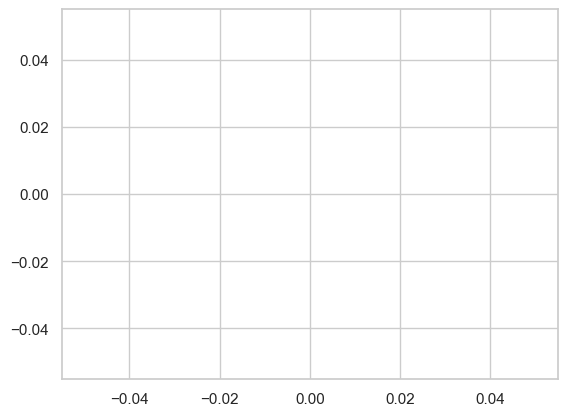

In [52]:
org_counts = df_clean[df_clean['ind_or_org'].eq('org')]['orgName'].value_counts().head(12)

org_counts.plot(kind='barh', color='#8C564B')

plt.title('Top organization Nobel laureates')
plt.xlabel('Count')
plt.ylabel('Organization')
plt.tight_layout()
plt.savefig(outdir / 'insight10_org_count.png')
plt.show()

### Insight #11

Question: What is the relationship between category and award amount?

Analysis: I compared the mean prize amount by category and qualified by whether the category is science or humanities.

Visualization: Boxplot or bar chart of category prize amounts.

Finding: Prize amounts vary across categories and may show historical structure or category-specific prize funding.

Interpretation: Prize amount is not a simple measure of scientific importance; the dataset records a financial field that may differ by category and year.

Follow-up: Is the prize amount distribution stable over time or has it increased by decade?


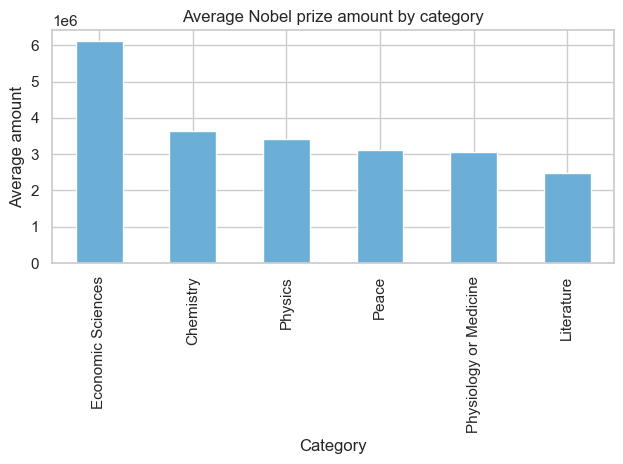

In [50]:
category_amount = df_clean.groupby('category')['prizeAmount'].mean().sort_values(ascending=False)
category_amount.plot(kind='bar', color='#6BAED6')
plt.title('Average Nobel prize amount by category')
plt.xlabel('Category')
plt.ylabel('Average amount')
plt.tight_layout()
plt.savefig(outdir / 'insight11_amount_by_category.png')
plt.show()

### Insight #12

Question: Is there an age-fatigue pattern or unusual age distribution across categories?

Analysis: I inspected age distribution and looked at the extremes of the `age_awarded` field.

Visualization: Histogram of age at award.

Finding: Most winners are recognized in the 40s–70s age range, but there are outliers where winners were awarded at much younger or older ages.

Interpretation: These age extremes reveal that Nobel awards can be given to very young scientists as well as late career figures, depending on the field and historical era.

Follow-up: Which categories produce the youngest and oldest winners, and how does this compare with the category-specific career lengths?


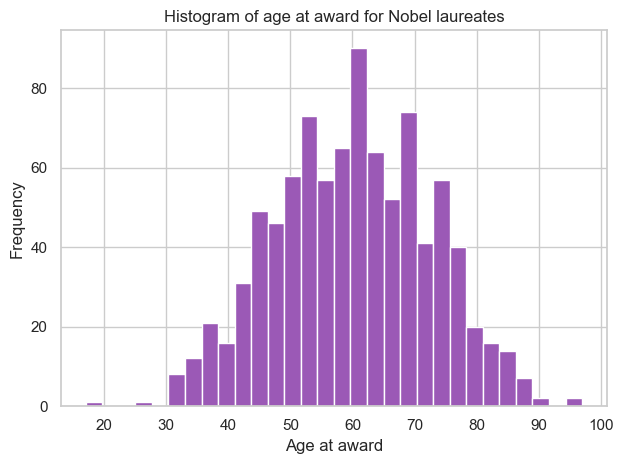

In [51]:
df_clean['age_awarded'].dropna().plot(kind='hist', bins=30, color='#9B59B6')
plt.title('Histogram of age at award for Nobel laureates')
plt.xlabel('Age at award')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig(outdir / 'insight12_age_histogram.png')
plt.show()

## Final Summary

### Key Findings

1. The dataset demonstrates a long-term male dominance in Nobel records, though female representation has improved over decades.
2. Country concentration is very high, with the USA, UK, and Germany producing the most winners.
3. Category-specific gender and age patterns differ significantly, meaning one global gender-count is not enough to describe the dataset.
4. Female representation changes by category and decade, indicating a time- and field-based shift.
5. A small group of individual awardees and institutions appear repeatedly, highlighting exceptional and institutional patterns.
6. Prize amounts differ by category and may reflect historical funding changes.
7. Age-at-award distributions show science and humanities follow different career paths.

What surprised me most about the Nobel Prize dataset? The strongest surprise is that a few high-level summary numbers hide very different structure by category, country, and time.

What additional analysis would I perform if I had more information or additional data? I would combine this dataset with broader historical population, institutional funding, and geopolitical data to explain why certain countries and categories dominate.
